# Sentinel-2 Vegetation Analysis

In [11]:
# Import libraries
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## 1. Raster Data Inspection

In [12]:
# Open the raster and inspect its metadata
raster_path = "data/sentinel2_small.tif"

with rasterio.open(raster_path) as src:
    print("Number of bands:", src.count)
    print("Image width:", src.width)
    print("Image height:", src.height)
    print("Coordinate reference system:", src.crs)
    print("Pixel resolution:", src.res)
    print("Data type:", src.dtypes)

Number of bands: 4
Image width: 1024
Image height: 1024
Coordinate reference system: EPSG:32633
Pixel resolution: (10.0, 10.0)
Data type: ('uint16', 'uint16', 'uint16', 'uint16')


In [13]:
# Check no data points
with rasterio.open(raster_path) as src:
    print("NoData value:", src.nodata)
    print("Zero pixels in red:", np.sum(src.read(3) == 0))
    print("Zero pixels in NIR:", np.sum(src.read(4) == 0))

NoData value: 0.0
Zero pixels in red: 0
Zero pixels in NIR: 0


## 2. Band Descriptions and Metadata

In [14]:
# Open the raster and inspect its band descriptions and metadata
with rasterio.open(raster_path) as src:
    print("Band description:", src.descriptions)
    print("Band metadata:", src.tags())
    print("Raster metadata:", src.profile)

Band description: ('blue', 'green', 'red', 'nir')
Band metadata: {'ACQUISITION_DATETIME': '2023-09-07T10:00:31.024000Z', 'MGRS_TILE': '33UUP', 'SOURCE': 'Copernicus Sentinel-2 L2A via Microsoft Planetary Computer', 'STAC_ITEM': 'S2A_MSIL2A_20230907T100031_R122_T33UUP_20230907T213241', 'AREA_OR_POINT': 'Area'}
Raster metadata: {'driver': 'GTiff', 'dtype': 'uint16', 'nodata': 0.0, 'width': 1024, 'height': 1024, 'count': 4, 'crs': CRS.from_wkt('PROJCS["WGS 84 / UTM zone 33N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",15],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["

## 3. Natural-Color Composite

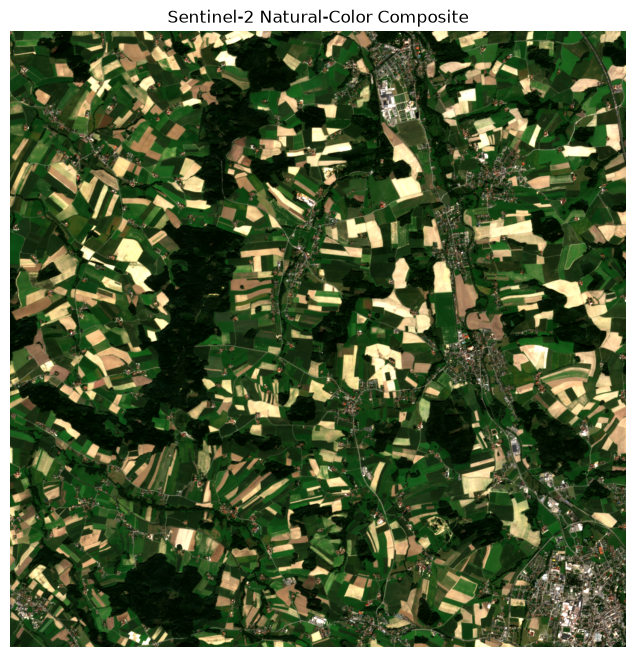

In [15]:
# Read the red, green, and blue bands
with rasterio.open(raster_path) as src:
    red = src.read(3).astype("float32")
    green = src.read(2).astype("float32")
    blue = src.read(1).astype("float32")

# Apply a percentile stretch for visualization
rgb = np.stack([red, green, blue], axis=-1)
lower = np.percentile(rgb, 2)
upper = np.percentile(rgb, 98)
rgb_display = np.clip((rgb - lower) / (upper - lower), 0, 1)

# Display the natural-color composite
plt.figure(figsize=(8, 8))
plt.imshow(rgb_display)
plt.title("Sentinel-2 Natural-Color Composite")
plt.axis("off")
plt.show()

## 4. Near-Infrared Visualization

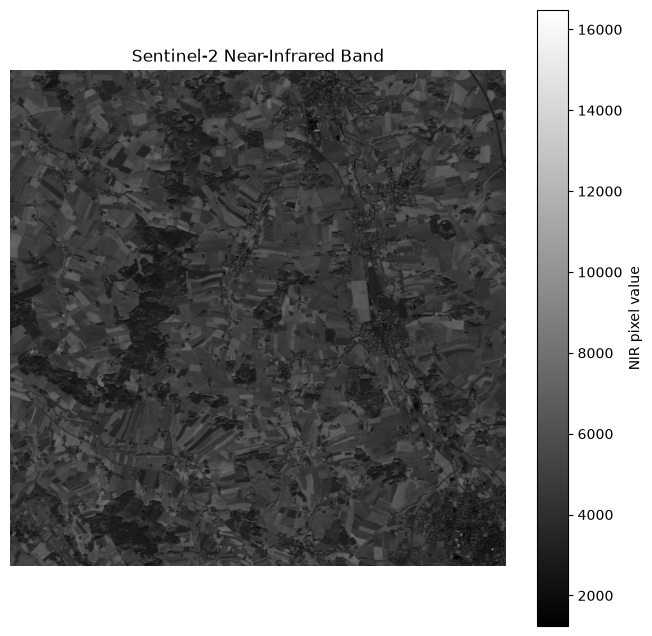

In [16]:
# Read and display the near-infrared band
with rasterio.open(raster_path) as src:
    nir = src.read(4).astype("float32")

plt.figure(figsize=(8, 8))
plt.imshow(nir, cmap="gray")
plt.colorbar(label="NIR pixel value")
plt.title("Sentinel-2 Near-Infrared Band")
plt.axis("off")
plt.show()

## 5. NDVI Calculation

In [17]:
# Read the red and near-infrared bands
with rasterio.open(raster_path) as src:
    red = src.read(3).astype("float32")
    nir = src.read(4).astype("float32")

# Calculate NDVI while avoiding division by zero
denominator = nir + red

ndvi = np.divide(
    nir - red,
    denominator,
    out=np.full_like(nir, np.nan),
    where=denominator != 0
)

# Display the NDVI statistics
print("Minimum NDVI:", np.nanmin(ndvi))
print("Maximum NDVI:", np.nanmax(ndvi))
print("Mean NDVI:", np.nanmean(ndvi))

Minimum NDVI: -0.107165106
Maximum NDVI: 0.73665184
Mean NDVI: 0.4434439


## 6. NDVI Visualization

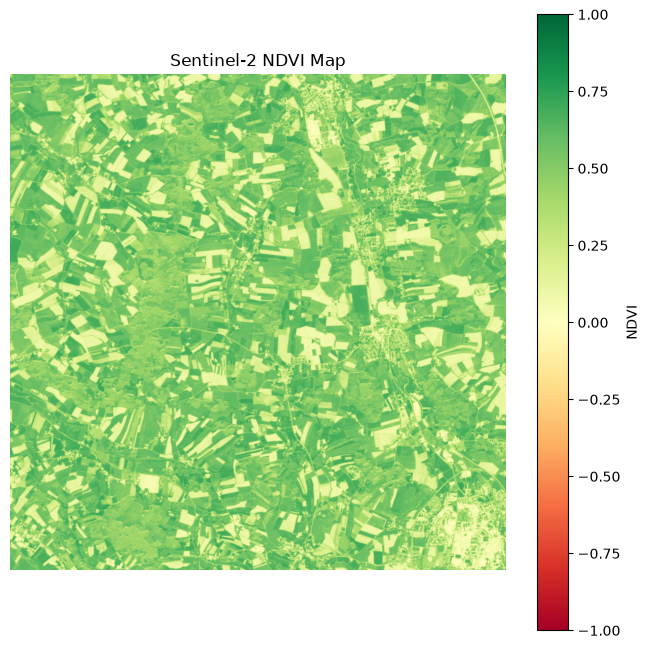

In [18]:
# Display the NDVI map
plt.figure(figsize=(8,8))
plt.imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
plt.colorbar(label="NDVI")
plt.title("Sentinel-2 NDVI Map")
plt.axis("off")
plt.show()

## 7. NDVI Distribution

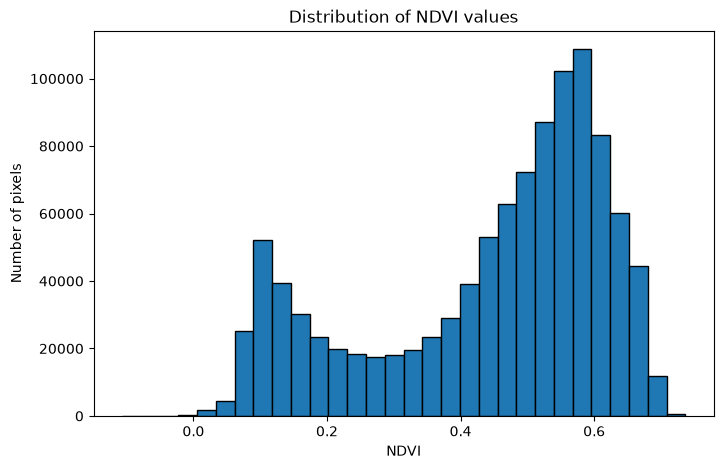

In [19]:
# Plot the distribution of NDVI values
valid_ndvi = ndvi[np.isfinite(ndvi)]

plt.figure(figsize=(8,5))
plt.hist(valid_ndvi, bins=30, edgecolor="black")
plt.xlabel("NDVI")
plt.ylabel("Number of pixels")
plt.title("Distribution of NDVI values")
plt.show()

## 8. Summary Statistics

In [20]:
# Create a summary table of NDVI statistics
ndvi_summary = pd.DataFrame ({
    "statistic": ["minimum", "maximum", "mean"],
    "ndvi_value": [
        np.nanmin(ndvi),
        np.nanmax(ndvi),
        np.nanmean(ndvi)
    ]
})

## 9. Export Results

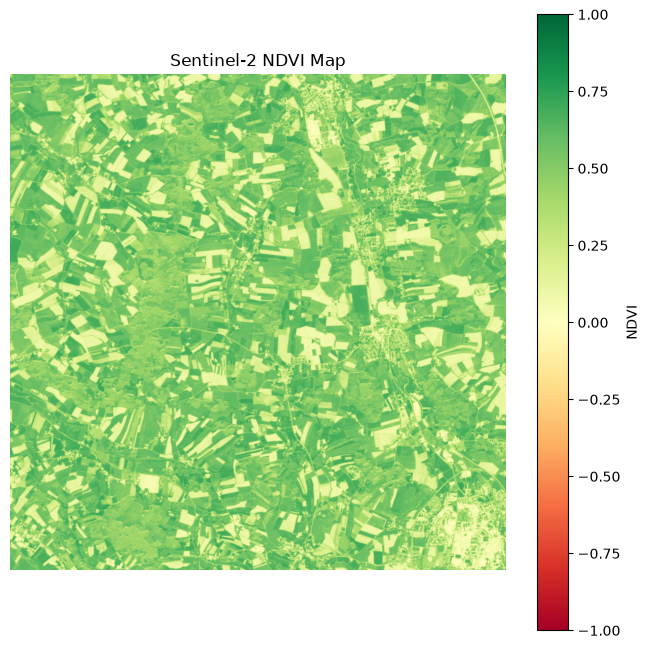

,statistic,ndvi_value
0,minimum,-0.107165
1,maximum,0.736652
2,mean,0.443444


In [21]:
# Save the NDVI map as a PNG image
plt.figure(figsize=(8, 8))
plt.imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
plt.colorbar(label="NDVI")
plt.title("Sentinel-2 NDVI Map")
plt.axis("off")
plt.savefig("ndvi_map.png", dpi=300, bbox_inches="tight")
plt.show()

# Save the summary table as a CSV file
ndvi_summary.to_csv("ndvi_summary.csv", index=False)
ndvi_summary